In [1]:
from pathlib import Path
import mne
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
DATA_ROOT = Path(
    r"C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project"
    r"\project1_openneuro\data\ds003061"
)

print("Dataset found:", DATA_ROOT.exists())

Dataset found: True


In [3]:
subjects = sorted(DATA_ROOT.glob("sub-*"))

print("Number of subjects:", len(subjects))
print([s.name for s in subjects])

Number of subjects: 13
['sub-001', 'sub-002', 'sub-003', 'sub-004', 'sub-005', 'sub-006', 'sub-007', 'sub-008', 'sub-009', 'sub-010', 'sub-011', 'sub-012', 'sub-013']


In [4]:
subject = DATA_ROOT / "sub-001"

for file in subject.rglob("*"):
    if file.is_file():
        print(file.relative_to(DATA_ROOT))

sub-001\eeg\sub-001_task-P300_run-1_channels.tsv
sub-001\eeg\sub-001_task-P300_run-1_coordsystem.json
sub-001\eeg\sub-001_task-P300_run-1_eeg.json
sub-001\eeg\sub-001_task-P300_run-1_eeg.set
sub-001\eeg\sub-001_task-P300_run-1_electrodes.tsv
sub-001\eeg\sub-001_task-P300_run-1_events.json
sub-001\eeg\sub-001_task-P300_run-1_events.tsv
sub-001\eeg\sub-001_task-P300_run-2_channels.tsv
sub-001\eeg\sub-001_task-P300_run-2_coordsystem.json
sub-001\eeg\sub-001_task-P300_run-2_eeg.json
sub-001\eeg\sub-001_task-P300_run-2_eeg.set
sub-001\eeg\sub-001_task-P300_run-2_electrodes.tsv
sub-001\eeg\sub-001_task-P300_run-2_events.json
sub-001\eeg\sub-001_task-P300_run-2_events.tsv
sub-001\eeg\sub-001_task-P300_run-3_channels.tsv
sub-001\eeg\sub-001_task-P300_run-3_coordsystem.json
sub-001\eeg\sub-001_task-P300_run-3_eeg.json
sub-001\eeg\sub-001_task-P300_run-3_eeg.set
sub-001\eeg\sub-001_task-P300_run-3_electrodes.tsv
sub-001\eeg\sub-001_task-P300_run-3_events.json
sub-001\eeg\sub-001_task-P300_run-3_

In [5]:
eeg_files = sorted((subject / "eeg").glob("*.set"))

print("Number of EEG files:", len(eeg_files))

for file in eeg_files:
    print(file.name)

Number of EEG files: 3
sub-001_task-P300_run-1_eeg.set
sub-001_task-P300_run-2_eeg.set
sub-001_task-P300_run-3_eeg.set


In [6]:
eeg_file = eeg_files[0]

raw = mne.io.read_raw_eeglab(
    eeg_file,
    preload=True
)

raw

C:\Users\Fafou\AppData\Local\Temp\ipykernel_27716\4093515965.py:3: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_27716\4093515965.py:3: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


<RawEEGLAB | sub-001_task-P300_run-1_eeg.set, 79 x 194048 (758.0 s), ~117.0 MiB, data loaded>

In [7]:
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Number of channels:", raw.info["nchan"])
print("Duration:", round(raw.times[-1] / 60, 2), "minutes")
print("Channels:")
print(raw.ch_names)
print(raw.annotations)

Sampling frequency: 256.0 Hz
Number of channels: 79
Duration: 12.63 minutes
Channels:
['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4', 'O2', 'EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']
<Annotations | 863 segments: ignore (3), noise (111), noise_with_reponse ...>


In [8]:
events, event_id = mne.events_from_annotations(raw)

print("Event codes:")
print(event_id)

print("\nNumber of events:", len(events))
print("\nFirst 10 events:")
print(events[:10])

Used Annotations descriptions: ['ignore', 'noise', 'noise_with_reponse', 'oddball', 'oddball_with_reponse', 'response', 'standard']
Event codes:
{'ignore': 1, 'noise': 2, 'noise_with_reponse': 3, 'oddball': 4, 'oddball_with_reponse': 5, 'response': 6, 'standard': 7}

Number of events: 863

First 10 events:
[[1139    0    7]
 [1346    0    7]
 [1604    0    7]
 [1876    0    7]
 [2138    0    7]
 [2374    0    7]
 [2629    0    7]
 [2896    0    7]
 [3159    0    7]
 [3420    0    7]]


In [9]:
from collections import Counter

event_counts = Counter(raw.annotations.description)

for event, count in event_counts.items():
    print(f"{event}: {count}")

standard: 522
noise_with_reponse: 1
response: 113
oddball: 1
noise: 111
oddball_with_reponse: 112
ignore: 3


In [10]:
oddball_events = events[events[:, 2] == event_id["oddball"]]

print("Number of oddball events:", len(oddball_events))
print("First 5 oddball events:")
print(oddball_events[:5])

Number of oddball events: 1
First 5 oddball events:
[[4963    0    4]]


In [11]:
oddball_codes = [
    event_id["oddball"],
    event_id["oddball_with_reponse"]
]

oddball_events = events[
    (events[:, 2] == oddball_codes[0]) |
    (events[:, 2] == oddball_codes[1])
]

print("Total oddball trials:", len(oddball_events))

Total oddball trials: 113


In [12]:
noise_codes = [
    event_id["noise"],
    event_id["noise_with_reponse"]
]

noise_events = events[
    (events[:, 2] == noise_codes[0]) |
    (events[:, 2] == noise_codes[1])
]

print("Total noise trials:", len(noise_events))

Total noise trials: 112


In [13]:
epochs = mne.Epochs(
    raw,
    events,
    event_id={
        "standard": event_id["standard"],
        "oddball/no_response": event_id["oddball"],
        "oddball/response": event_id["oddball_with_reponse"],
    },
    tmin=-0.2,
    tmax=0.8,
    baseline=(-0.2, 0),
    preload=True
)

epochs

Not setting metadata
635 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 635 events and 257 original time points ...
1 bad epochs dropped


<Epochs | 634 events (all good), -0.199 – 0.801 s (baseline -0.2 – 0 s), ~98.3 MiB, data loaded,
 'standard': 521
 'oddball/no_response': 1
 'oddball/response': 112>

In [14]:
"oddball/no_response"
"oddball/response"
epochs["oddball"]
print("Standard:", len(epochs["standard"]))
print("Oddball:", len(epochs["oddball"]))

Standard: 521
Oddball: 113


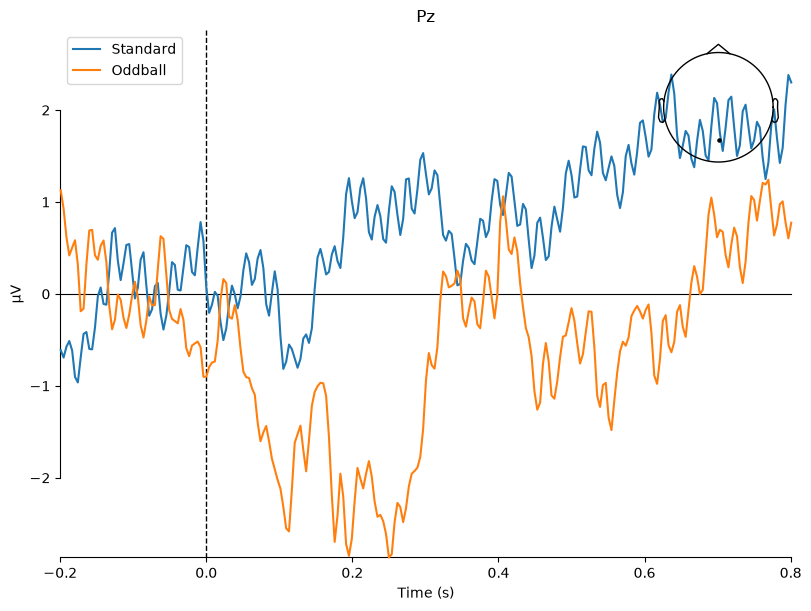

[<Figure size 800x600 with 2 Axes>]

In [15]:
standard_erp = epochs["standard"].average()
oddball_erp = epochs["oddball"].average()
mne.viz.plot_compare_evokeds(
    {
        "Standard": standard_erp,
        "Oddball": oddball_erp
    },
    picks="Pz"
)

In [17]:

# ============================================================
# EEG DATASET EXPLORATION - OPENNEURO DS003061
# ============================================================

from pathlib import Path
from collections import Counter
import json

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. DATASET INVENTORY
# ------------------------------------------------------------

DATA_ROOT = Path(
    r"C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project"
    r"\project1_openneuro\data\ds003061"
)

subjects = sorted(DATA_ROOT.glob("sub-*"))
recordings = sorted(DATA_ROOT.glob("sub-*/eeg/*_eeg.set"))

print("Subjects:", len(subjects))
print("EEG recordings:", len(recordings))

# Count files by extension to understand the dataset contents.
file_extensions = Counter(
    file.suffix.lower()
    for file in DATA_ROOT.rglob("*")
    if file.is_file()
)


print("\nFile formats:")
print(file_extensions)



Subjects: 13
EEG recordings: 39

File formats:
Counter({'.json': 120, '.tsv': 118, '.set': 39, '': 5, '.wav': 3, '.m': 1})


In [18]:

# ------------------------------------------------------------
# 2. LOAD ONE RECORDING
# ------------------------------------------------------------

eeg_file = (
    DATA_ROOT
    / "sub-001"
    / "eeg"
    / "sub-001_task-P300_run-1_eeg.set"
)

raw = mne.io.read_raw_eeglab(
    eeg_file,
    preload=True,
    verbose=False
)

sfreq = raw.info["sfreq"]

print("\nRecording:")
print("Sampling rate:", sfreq, "Hz")
print("Channels:", raw.info["nchan"])
print("Samples:", raw.n_times)
print("Duration:", round(raw.times[-1], 1), "seconds")
print("Bad channels marked:", raw.info["bads"])



Recording:
Sampling rate: 256.0 Hz
Channels: 79
Samples: 194048
Duration: 758.0 seconds
Bad channels marked: []


C:\Users\Fafou\AppData\Local\Temp\ipykernel_27716\2545821229.py:12: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_27716\2545821229.py:12: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


In [19]:


# ------------------------------------------------------------
# 3. INSPECT ALL CHANNELS
# ------------------------------------------------------------

channel_info = pd.DataFrame({
    "channel": raw.ch_names,
    "mne_type": raw.get_channel_types(),
    "index": np.arange(len(raw.ch_names))
})

# In this dataset, the first 64 channels are scalp EEG;
# the remaining 15 are auxiliary signals.
channel_info["group"] = np.where(
    channel_info["index"] < 64,
    "Scalp EEG",
    "Auxiliary"
)

print("\nCHANNEL INFORMATION")
display(channel_info)




CHANNEL INFORMATION


,channel,mne_type,index,group
0,Fp1,eeg,0,Scalp EEG
1,AF7,eeg,1,Scalp EEG
2,AF3,eeg,2,Scalp EEG
3,F1,eeg,3,Scalp EEG
4,F3,eeg,4,Scalp EEG
...,...,...,...,...
74,Erg1,misc,74,Auxiliary
75,Erg2,misc,75,Auxiliary
76,Resp,resp,76,Auxiliary
77,Plet,misc,77,Auxiliary


In [20]:

# ------------------------------------------------------------
# 4. EXTRACT ALL 79 SIGNALS FOR ONE SECOND
# ------------------------------------------------------------

# 'start' and 'stop' refer to sample indices, not seconds.
# At 256 Hz, one second contains 256 samples.
one_second = raw.get_data(
    start=0,
    stop=int(sfreq)
)

print("\nALL-CHANNEL DATA")
print("Array shape:", one_second.shape)
print("Array type:", type(one_second))
print("Numerical datatype:", one_second.dtype)

# Show a small sample of the numerical values.
# Rows = channels; columns = time samples.
preview = pd.DataFrame(
    one_second[:5, :8],
    index=raw.ch_names[:5]
)

display(preview)




ALL-CHANNEL DATA
Array shape: (79, 256)
Array type: <class 'numpy.ndarray'>
Numerical datatype: float64


,0,1,2,3,4,5,6,7
Fp1,-0.259367,-0.259368,-0.259369,-0.259367,-0.259367,-0.259368,-0.259368,-0.259368
AF7,-0.003544,-0.003530,-0.003533,-0.003555,-0.003555,-0.003547,-0.003552,-0.003540
AF3,0.000846,0.000857,0.000844,0.000834,0.000831,0.000838,0.000835,0.000843
F1,0.000359,0.000370,0.000355,0.000346,0.000337,0.000347,0.000342,0.000347
F3,0.005672,0.005689,0.005680,0.005668,0.005660,0.005672,0.005665,0.005673


In [21]:

# ------------------------------------------------------------
# 5. EXTRACT 10 SECONDS FROM Fz, Cz AND Pz
# ------------------------------------------------------------

channels = ["Fz", "Cz", "Pz"]

start_s = 100
duration_s = 10

# Convert seconds into integer sample indices.
start_sample = int(start_s * sfreq)
stop_sample = int((start_s + duration_s) * sfreq)

# Extract signals and their timestamps.
signal, times = raw.get_data(
    picks=channels,
    start=start_sample,
    stop=stop_sample,
    return_times=True
)

# MNE stores EEG in volts. Convert scalp EEG to microvolts.
signal_uv = signal * 1e6

print("\nSELECTED EEG DATA")
print("Shape:", signal_uv.shape)
print("Time range:", times[0], "to", times[-1], "seconds")




SELECTED EEG DATA
Shape: (3, 2560)
Time range: 100.0 to 109.99609375 seconds


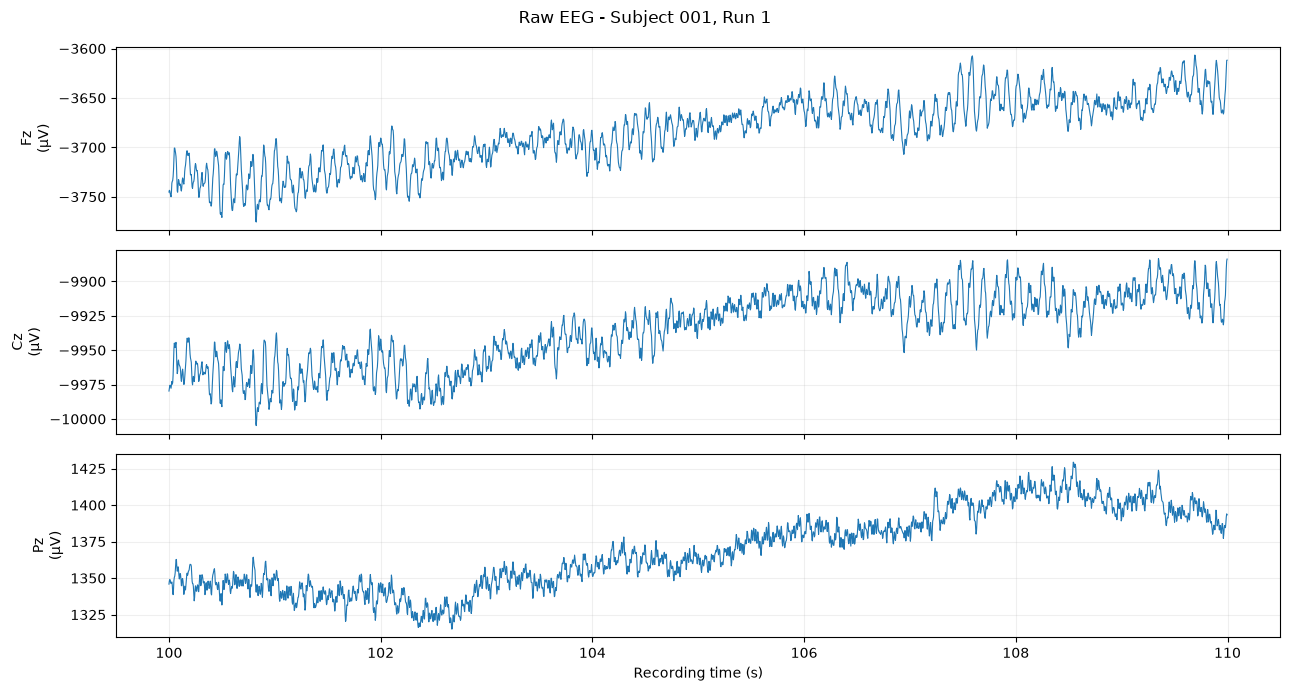

In [22]:

# ------------------------------------------------------------
# 6. PLOT THE EEG WAVEFORMS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(channels), 1,
    figsize=(13, 7),
    sharex=True
)

for i, channel in enumerate(channels):

    axes[i].plot(
        times,
        signal_uv[i],
        linewidth=0.8
    )

    axes[i].set_ylabel(f"{channel}\n(µV)")
    axes[i].grid(alpha=0.2)

axes[-1].set_xlabel("Recording time (s)")
fig.suptitle("Raw EEG - Subject 001, Run 1")

plt.tight_layout()
plt.show()



In [23]:

# ------------------------------------------------------------
# 7. EXPLORE ALL 64 SCALP EEG CHANNELS
# ------------------------------------------------------------

scalp_channels = raw.ch_names[:64]

# Extract the same 10-second window from all scalp channels.
scalp_data = raw.get_data(
    picks=scalp_channels,
    start=start_sample,
    stop=stop_sample
) * 1e6

# Summarize the signal amplitudes per electrode.
scalp_summary = pd.DataFrame({
    "channel": scalp_channels,
    "mean_uV": scalp_data.mean(axis=1),
    "std_uV": scalp_data.std(axis=1),
    "peak_to_peak_uV": np.ptp(scalp_data, axis=1)
})

print("\nCHANNELS WITH HIGHEST SIGNAL VARIABILITY")

display(
    scalp_summary
    .sort_values("std_uV", ascending=False)
    .head(10)
    .round(2)
)




CHANNELS WITH HIGHEST SIGNAL VARIABILITY


,channel,mean_uV,std_uV,peak_to_peak_uV
34,AF8,-15159.90,53.99,267.16
1,AF7,-2941.57,53.62,247.50
7,FT7,-9624.82,49.53,210.34
55,CP2,-2598.53,42.17,148.00
2,AF3,1412.62,40.65,197.72
51,T8,-5121.48,37.33,199.25
54,CP4,2303.11,36.82,148.16
22,P7,-3296.60,36.32,180.31
12,C3,-1291.75,35.79,157.78
32,Fpz,-7968.28,34.22,204.69


In [24]:

# ------------------------------------------------------------
# 8. EXPLORE AUXILIARY SIGNALS
# ------------------------------------------------------------

aux_channels = raw.ch_names[64:]

aux_data = raw.get_data(
    picks=aux_channels,
    start=start_sample,
    stop=stop_sample
)

# Keep native/imported units here, since not every
# auxiliary channel represents a scalp voltage.
aux_summary = pd.DataFrame({
    "channel": aux_channels,
    "min_value": aux_data.min(axis=1),
    "max_value": aux_data.max(axis=1),
    "std_value": aux_data.std(axis=1)
})

print("\nAUXILIARY CHANNELS")
display(aux_summary)




AUXILIARY CHANNELS


,channel,min_value,max_value,std_value
0,EXG1,8.150813e-03,8.374844e-03,3.767245e-05
1,EXG2,1.708695e-02,1.723045e-02,3.135678e-05
2,EXG3,8.591312e-03,8.766687e-03,2.890932e-05
3,EXG4,5.592599e-03,5.756380e-03,3.547543e-05
4,EXG5,-1.171640e-02,-1.133925e-02,9.568423e-05
5,EXG6,-2.593808e-01,-2.593786e-01,2.902942e-07
6,EXG7,-2.594176e-01,-2.594159e-01,2.576939e-07
7,EXG8,-6.614472e-03,-6.459098e-03,2.587859e-05
8,GSR1,-4.843750e-07,-4.843750e-07,0.000000e+00
9,GSR2,-4.843750e-07,-4.843750e-07,0.000000e+00


In [25]:

# ------------------------------------------------------------
# 9. EVENT ANNOTATIONS
# ------------------------------------------------------------

annotations = pd.DataFrame({
    "onset_s": raw.annotations.onset,
    "duration_s": raw.annotations.duration,
    "description": raw.annotations.description
})

print("\nFIRST 15 EVENTS")
display(annotations.head(15))

print("\nEVENT COUNTS")
display(
    annotations["description"]
    .value_counts()
    .rename_axis("event")
    .reset_index(name="count")
)




FIRST 15 EVENTS


,onset_s,duration_s,description
0,4.449219,0.0,standard
1,5.257812,0.0,standard
2,6.265625,0.0,standard
3,7.328125,0.0,standard
4,8.351562,0.0,standard
5,9.273438,0.0,standard
6,10.269531,0.0,standard
7,11.312500,0.0,standard
8,12.339844,0.0,standard
9,13.359375,0.0,standard



EVENT COUNTS


,event,count
0,standard,522
1,response,113
2,oddball_with_reponse,112
3,noise,111
4,ignore,3
5,noise_with_reponse,1
6,oddball,1


In [26]:

# ------------------------------------------------------------
# 10. PARTICIPANT INFORMATION
# ------------------------------------------------------------

participants_file = DATA_ROOT / "participants.tsv"

if participants_file.exists():

    participants = pd.read_csv(
        participants_file,
        sep="\t"
    )

    print("\nPARTICIPANT METADATA")
    display(participants)

else:
    print("No participants.tsv file found.")




PARTICIPANT METADATA


,participant_id,gender,age,Ethnicity,Air_conditioning
0,sub-001,F,44,Indian,on
1,sub-002,F,32,Indian,on
2,sub-003,F,28,Non_indian,off
3,sub-004,M,35,Indian,off
4,sub-005,F,49,Non_indian,off
5,sub-006,F,27,Non_indian,off
6,sub-007,M,33,Indian,on
7,sub-008,M,35,Indian,off
8,sub-009,F,31,Non_indian,on
9,sub-010,M,24,Indian,on


In [27]:

# ------------------------------------------------------------
# 11. BIDS FILES FOR THIS RECORDING
# ------------------------------------------------------------

run_prefix = eeg_file.stem.removesuffix("_eeg")

print("\nFILES ASSOCIATED WITH THIS RUN")

for file in sorted(eeg_file.parent.glob(run_prefix + "*")):
    print(file.name)

# Inspect event and channel tables if available.
for suffix in ["events.tsv", "channels.tsv"]:

    file = eeg_file.parent / f"{run_prefix}_{suffix}"

    if file.exists():

        print(f"\n{file.name}")

        table = pd.read_csv(
            file,
            sep="\t"
        )

        print("Columns:", table.columns.tolist())
        display(table.head(10))




FILES ASSOCIATED WITH THIS RUN
sub-001_task-P300_run-1_channels.tsv
sub-001_task-P300_run-1_coordsystem.json
sub-001_task-P300_run-1_eeg.json
sub-001_task-P300_run-1_eeg.set
sub-001_task-P300_run-1_electrodes.tsv
sub-001_task-P300_run-1_events.json
sub-001_task-P300_run-1_events.tsv

sub-001_task-P300_run-1_events.tsv
Columns: ['onset', 'duration', 'sample', 'trial_type', 'response_time', 'stim_file', 'value']


,onset,duration,sample,trial_type,response_time,stim_file,value
0,4.449219,NaN,1139,stimulus,NaN,NaN,standard
1,5.257812,NaN,1346,stimulus,NaN,NaN,standard
2,6.265625,NaN,1604,stimulus,NaN,NaN,standard
3,7.328125,NaN,1876,stimulus,NaN,NaN,standard
4,8.351562,NaN,2138,stimulus,NaN,NaN,standard
5,9.273438,NaN,2374,stimulus,NaN,NaN,standard
6,10.269531,NaN,2629,stimulus,NaN,NaN,standard
7,11.312500,NaN,2896,stimulus,NaN,NaN,standard
8,12.339844,NaN,3159,stimulus,NaN,NaN,standard
9,13.359375,NaN,3420,stimulus,NaN,NaN,standard



sub-001_task-P300_run-1_channels.tsv
Columns: ['name', 'type', 'units']


,name,type,units
0,Fp1,EEG,microV
1,AF7,EEG,microV
2,AF3,EEG,microV
3,F1,EEG,microV
4,F3,EEG,microV
5,F5,EEG,microV
6,F7,EEG,microV
7,FT7,EEG,microV
8,FC5,EEG,microV
9,FC3,EEG,microV


In [28]:

# ------------------------------------------------------------
# 12. DATASET JSON METADATA
# ------------------------------------------------------------

for filename in [
    "dataset_description.json",
    "participants.json",
    "task-P300_events.json"
]:

    file = DATA_ROOT / filename

    if file.exists():

        with open(file, encoding="utf-8") as f:
            metadata = json.load(f)

        print(f"\n{filename}")
        print("Fields:", list(metadata.keys()))

        # Display the metadata without changing it.
        display(metadata)




dataset_description.json
Fields: ['Name', 'ReferencesAndLinks', 'BIDSVersion', 'License', 'Authors', 'DatasetDOI', 'HowToAcknowledge', 'HEDVersion']


{'Name': 'EEG data from an auditory oddball task',
 'ReferencesAndLinks': ['No bibliographic reference other than the DOI for this dataset'],
 'BIDSVersion': 'v1.2.1',
 'License': 'CC0',
 'Authors': ['Arnaud Delorme'],
 'DatasetDOI': 'doi:10.18112/openneuro.ds003061.v1.1.2',
 'HowToAcknowledge': 'Delorme, A. (2020) EEG data from an auditory oddball task. Data archive openneuro.org. 10.18112/openneuro.ds003061.v1.0.0.',
 'HEDVersion': '8.0.0'}


participants.json
Fields: ['participant_id', 'gender', 'age', 'Air_conditioning', 'Ethnicity']


{'participant_id': {'LongName': 'Participant identifier',
  'Description': 'Unique participant identifier'},
 'gender': {'Description': 'Sex of the participant',
  'Levels': {'M': 'male', 'F': 'female'}},
 'age': {'Description': 'age of the participant', 'Units': 'years'},
 'Air_conditioning': {'Description': 'Air Conditioning - could create interference so noted here',
  'Levels': {'on': 'Air Conditioning was on  - temperature at or below 25C',
   'off': 'Air Conditioning was off - temperature at or above 25C'}},
 'Ethnicity': {'Levels': {'Indian': 'Participant of Indian origin',
   'Non_indian': 'Participant of non-Indian origin (Caucasian, etc...)'}}}


task-P300_events.json
Fields: ['duration', 'sample', 'trial_type', 'response_time', 'stim_file', 'onset', 'value']


{'duration': {'LongName': 'Event duration',
  'Description': 'Duration of the event (measured from onset) in seconds',
  'Units': 'second'},
 'sample': {'LongName': 'Sample',
  'Description': 'Onset of the event according to the sampling scheme of the recorded modality (i.e., referring to the raw data file that the events.tsv file accompanies).'},
 'trial_type': {'LongName': 'Event categorization',
  'Description': 'Type of event',
  'Levels': {'stimulus': 'Auditory stimulus',
   'responses': 'Behavioral response'}},
 'response_time': {'LongName': 'Response time',
  'Description': 'Latency of button press after auditory stimulus',
  'Units': 'second',
  'Levels': {'Units': 'millisecond'}},
 'stim_file': {'LongName': 'Stimulus file location',
  'Description': 'Represents the location of the stimulus file (image, video, sound etc.) presented at the given onset time. They should be stored in the /stimuli folder (under the root folder of the dataset; with optional subfolders). The values u

In [31]:

# ------------------------------------------------------------
# 13. UNDERSTAND THE EPOCH DATA STRUCTURE
# ------------------------------------------------------------

events, event_id = mne.events_from_annotations(
    raw,
    verbose=False
)

# Gather available standard and oddball event codes.
standard_code = event_id["standard"]

oddball_codes = [
    event_id[name]
    for name in ["oddball", "oddball_with_reponse"]
    if name in event_id
]

# Select the two stimulus categories.
standard_mask = events[:, 2] == standard_code
oddball_mask = np.isin(events[:, 2], oddball_codes)

keep = standard_mask | oddball_mask

selected_events = events[keep].copy()

# Normalize labels:
# 1 = standard; 2 = oddball.
selected_events[:, 2] = np.where(
    standard_mask[keep],
    1,
    2
)

epochs = mne.Epochs(
    raw,
    selected_events,
    event_id={"standard": 1, "oddball": 2},
    tmin=-0.2,
    tmax=0.8,
    baseline=(-0.2, 0),
    picks=["Fz", "Cz", "Pz"],
    preload=True,
    verbose=False
)

# This is now a 3D array:
# trials x channels x time samples.
epoch_data = epochs.get_data()

print("\nEPOCH DATA")
print("Shape:", epoch_data.shape)
print("Number of trials:", epoch_data.shape[0])
print("Number of channels:", epoch_data.shape[1])
print("Time samples per trial:", epoch_data.shape[2])
print("Epoch channels:", epochs.ch_names)

# Inspect the first trial, only the first 10 samples.
first_trial = pd.DataFrame(
    epoch_data[0, :, :10].T * 1e6,
    columns=epochs.ch_names
)

print("\nFIRST TRIAL - FIRST 10 SAMPLES (µV)")
display(first_trial.round(3))



EPOCH DATA
Shape: (634, 3, 257)
Number of trials: 634
Number of channels: 3
Time samples per trial: 257
Epoch channels: ['Fz', 'Cz', 'Pz']

FIRST TRIAL - FIRST 10 SAMPLES (µV)


,Fz,Cz,Pz
0,16.398,14.208,6.750
1,12.148,10.927,4.062
2,6.867,7.333,4.156
3,6.711,8.677,7.625
4,7.242,10.583,10.156
5,6.742,7.614,9.281
6,5.117,4.020,5.406
7,3.930,2.333,1.156
8,5.711,2.489,-1.594
9,6.836,0.520,-1.594
